# Marketing Channel Performance: EDA and Statistical Testing

This notebook evaluates campaign performance across Google Ads, Meta Ads, and TikTok Ads. It covers data quality, aggregate marketing metrics, visual exploration, pairwise tests, multiple-comparison control, power analysis, and an executive recommendation.

## 1. Exploratory Data Analysis  - EDA

- **Dataset:** Global Ads Performance (Google, Meta, TikTok)
- **Source:** [Kaggle](https://www.kaggle.com/datasets/nudratabbas/global-ads-performance-google-meta-tiktok/data)
- **Why this dataset:** It contains campaign-day observations for three comparable advertising platforms, with impressions, clicks, spend, conversions, and revenue. That supports both continuous metric comparisons and conversion-rate tests.
- **Unit of observation:** One row is a daily advertising campaign record. The analysis therefore treats rows as campaign-day observations and reports that assumption as a limitation.
- **Scope note:** The requested business scenario mentions seven channels, but this file contains three platforms. The recommendation below is therefore a provisional three-platform allocation, not a seven-channel budget plan.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from pathlib import Path
from IPython.display import Markdown, display

from scipy import stats
from scipy.stats import fisher_exact
try:
    from scipy.stats import false_discovery_control
except ImportError:
    def false_discovery_control(pvalues, method='bh'):
        values = np.asarray(pvalues, dtype=float)
        order = np.argsort(values)
        ranked = values[order]
        adjusted = ranked * len(values) / np.arange(1, len(values) + 1)
        adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
        result = np.empty_like(adjusted)
        result[order] = np.minimum(adjusted, 1.0)
        return result

sns.set_theme(style='whitegrid', context='notebook')
ALPHA = 0.05
DATA_PATH = Path('global_ads_performance_dataset.csv')
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)

In [ ]:
# Load the local copy of the Kaggle dataset. Existing CTR/CPC/CPA/ROAS values are used as provided.
COLUMN_MAP = {'platform': 'channel', 'ad_spend': 'cost', 'CTR': 'ctr', 'CPC': 'cpc', 'CPA': 'cpa', 'ROAS': 'roas'}
raw = pd.read_csv(DATA_PATH).rename(columns=COLUMN_MAP)
required = ['date', 'channel', 'impressions', 'clicks', 'conversions', 'cost', 'revenue']
missing_required = sorted(set(required) - set(raw.columns))
if missing_required:
    raise ValueError(f'Missing required columns: {missing_required}')

print(f'Shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns')
print(f'Channels: {raw.channel.nunique()} -> {sorted(raw.channel.unique())}')
raw.info()
display(raw.head())

In [13]:
# Convert types, remove duplicate or impossible records, and calculate row-level metrics.
df = raw.copy()
df['date'] = pd.to_datetime(df['date'], errors='coerce')
numeric_cols = ['impressions', 'clicks', 'conversions', 'cost', 'revenue', 'ctr', 'cpc', 'cpa', 'roas']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

before = len(df)
df = df.drop_duplicates().dropna(subset=required)
invalid = (
    (df[numeric_cols] < 0).any(axis=1)
    | (df.clicks > df.impressions)
    | (df.conversions > df.clicks)
)
df = df.loc[~invalid].copy()

df['conversion_rate'] = df.conversions.div(df.clicks).replace([np.inf, -np.inf], np.nan)
df['profit'] = df.revenue - df.cost
df['profit_margin'] = df.profit.div(df.revenue).replace([np.inf, -np.inf], np.nan)

print(f'Removed {before - len(df)} duplicate or invalid rows; retained {len(df):,}.')
print(f'Date range: {df.date.min().date()} to {df.date.max().date()} ({df.date.nunique()} dates)')
print(f'Rows per channel:\n{df.channel.value_counts().sort_index()}')
print(f'\nMissing values after cleaning:\n{df.isna().sum()[df.isna().sum() > 0]}')
df.to_csv(OUT / 'marketing_data.csv', index=False)
display(df.describe(include='number').T.round(3))

Removed 0 duplicate or invalid rows; retained 1,800.
Date range: 2024-01-01 to 2024-12-30 (360 dates)
Rows per channel:
channel
Google Ads    720
Meta Ads      630
TikTok Ads    450
Name: count, dtype: int64

Missing values after cleaning:
Series([], dtype: int64)


,count,mean,std,min,25%,50%,75%,max
impressions,1800.0,102919.019,55740.901,5059.000,54948.000,103653.000,150470.250,199650.000
clicks,1800.0,3962.676,2941.858,91.000,1678.000,3318.000,5628.000,16660.000
ctr,1800.0,0.038,0.017,0.009,0.025,0.036,0.050,0.096
cpc,1800.0,1.573,0.801,0.280,0.950,1.460,2.050,3.950
cost,1800.0,6171.527,5776.997,58.000,1966.588,4393.860,8455.830,38453.320
conversions,1800.0,181.562,171.424,2.000,59.000,130.000,252.250,1151.000
cpa,1800.0,46.609,41.186,4.800,20.202,33.375,56.812,335.860
revenue,1800.0,30101.850,34560.033,142.690,7275.758,18362.965,38963.385,295028.260
roas,1800.0,6.450,6.591,0.130,2.170,4.295,8.212,49.000
conversion_rate,1800.0,0.045,0.020,0.009,0.028,0.046,0.063,0.080


### Transformations made

| Metric | Formula | What it tells you |
| --- | --- | --- |
| **CTR** (Click-Through Rate) | clicks ÷ impressions × 100 | How often people who see the ad click it, which shows how engaging the ad is |
| **CPC** (Cost Per Click) | cost ÷ clicks | The average price you pay for each click |
| **CPA** (Cost Per Acquisition) | cost ÷ conversions | What it costs to get one conversion (a sale, sign-up, or lead) |
| **ROAS** (Return On Ad Spend) | revenue ÷ cost | How much revenue each dollar of ad spend brings in |
| **Conversion Rate** | conversions ÷ clicks × 100 | The share of clicks that turn into conversions, which shows how well the landing page and offer perform |
| **Profit** | revenue − cost | The money left after ad spend, which is not true profit if other costs apply |
| **Profit Margin** | profit ÷ revenue × 100 | The share of revenue you keep after ad spend |

Dates and core measures were coerced to their appropriate types. Exact duplicate rows, missing required fields, negative measures, clicks greater than impressions, and conversions greater than clicks were excluded. CTR, CPC, CPA, and ROAS are retained directly from the database. Only conversion rate, profit, and profit margin are derived here. Infinite values are converted to missing values. The cleaned file is saved as `outputs/marketing_data.csv`.

In [14]:
# Aggregate totals support volume and profit reporting; CTR/CPC/CPA/ROAS below are database values summarized by channel, not recalculated.
summary = (df.groupby('channel')
    .agg(rows=('channel', 'size'), impressions=('impressions', 'sum'),
         clicks=('clicks', 'sum'), conversions=('conversions', 'sum'),
         cost=('cost', 'sum'), revenue=('revenue', 'sum'),
         ctr=('ctr', 'mean'), cpc=('cpc', 'mean'), cpa=('cpa', 'mean'), roas=('roas', 'mean'))
)
summary['conversion_rate'] = summary.conversions / summary.clicks
summary['profit'] = summary.revenue - summary.cost
summary['profit_margin'] = summary.profit / summary.revenue
summary = summary.sort_values('roas', ascending=False)
summary.to_csv(OUT / 'channel_summary.csv')
display(summary.style.format({'ctr': '{:.2%}', 'conversion_rate': '{:.2%}', 'cpa': '${:,.2f}', 'roas': '{:.2f}x', 'cost': '${:,.0f}', 'revenue': '${:,.0f}', 'profit': '${:,.0f}', 'profit_margin': '{:.2%}'}))

,rows,impressions,clicks,conversions,cost,revenue,ctr,cpc,cpa,roas,conversion_rate,profit,profit_margin
channel,,,,,,,,,,,,,
TikTok Ads,450,47049590,2599931,122452,"$2,653,419","$20,223,540",5.50%,1.009978,$29.20,9.54x,4.71%,"$17,570,122",86.88%
Meta Ads,630,64403494,1596736,73262,"$2,106,062","$11,926,046",2.50%,1.316095,$39.10,6.92x,4.59%,"$9,819,984",82.34%
Google Ads,720,73801150,2936149,131098,"$6,349,269","$22,033,745",3.99%,2.149069,$64.06,4.11x,4.46%,"$15,684,476",71.18%


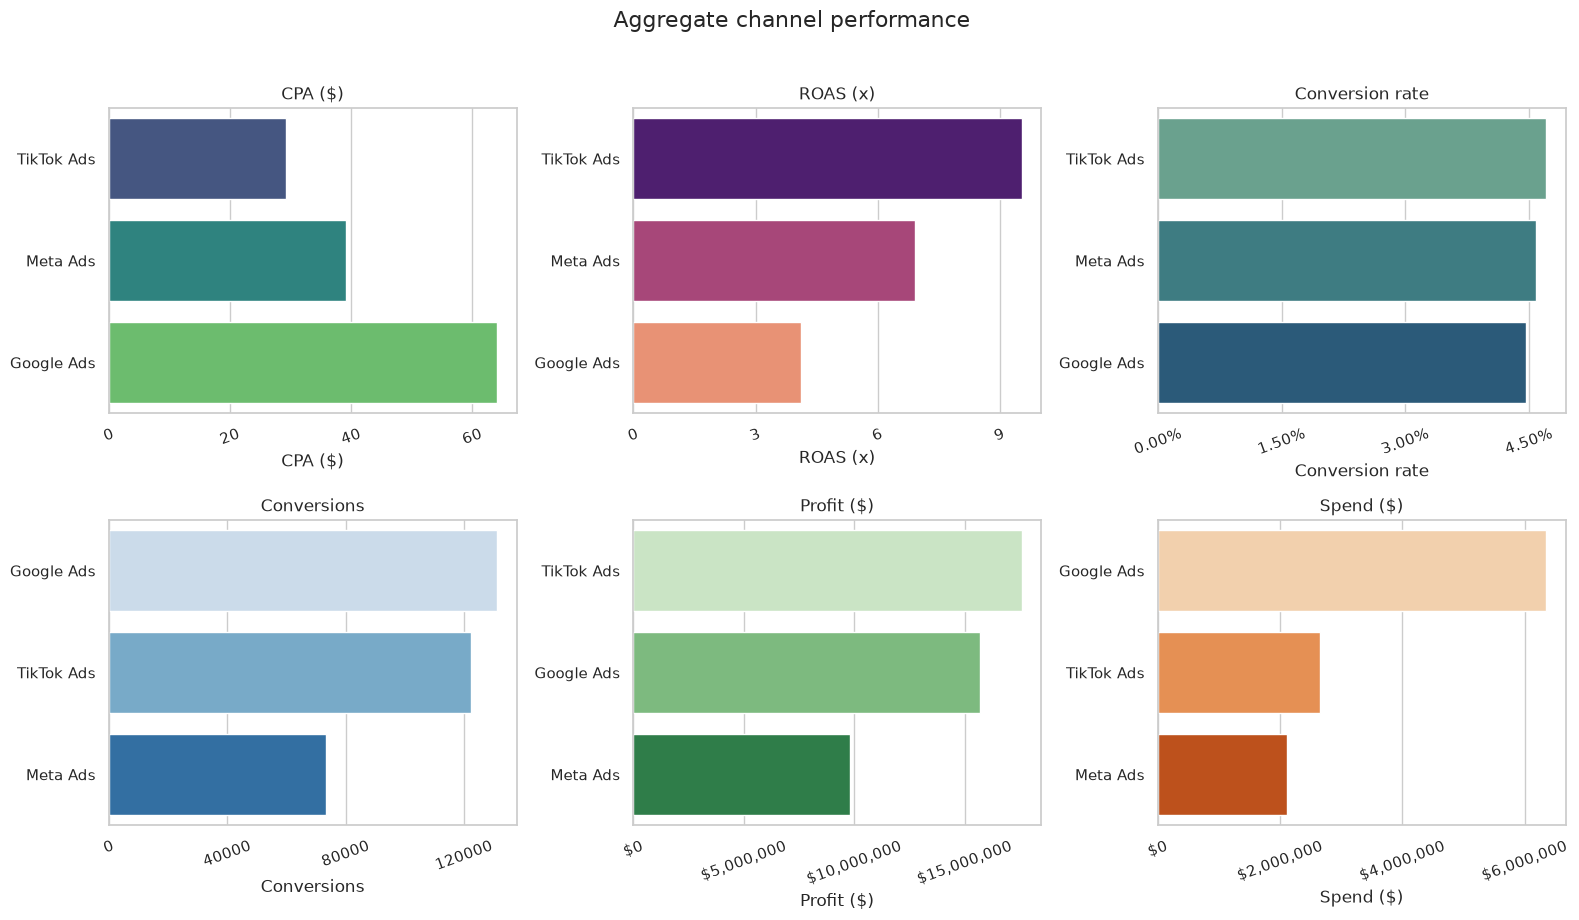

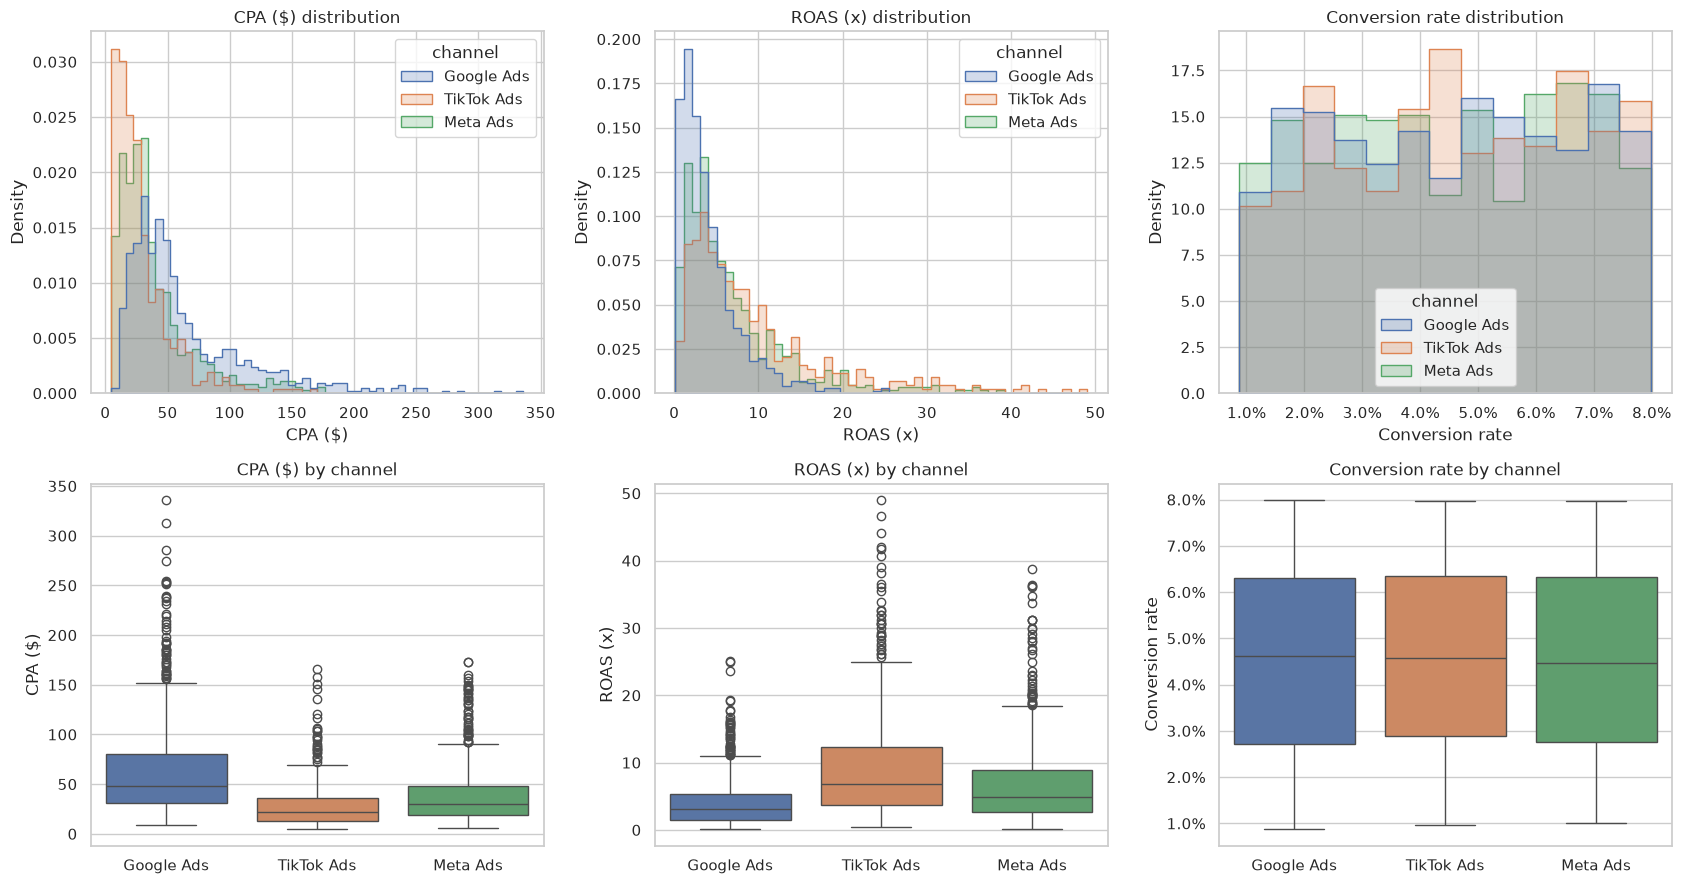

In [15]:
# Group-level overview: lower CPA is better; higher ROAS, conversion rate, profit, and conversions are better.
plot_specs = [('cpa', 'CPA ($)', 'viridis'), ('roas', 'ROAS (x)', 'magma'),
              ('conversion_rate', 'Conversion rate', 'crest'), ('conversions', 'Conversions', 'Blues'),
              ('profit', 'Profit ($)', 'Greens'), ('cost', 'Spend ($)', 'Oranges')]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (metric, label, palette) in zip(axes.flat, plot_specs):
    values = summary.sort_values(metric, ascending=(metric == 'cpa'))
    sns.barplot(data=values.reset_index(), y='channel', x=metric, ax=ax, hue='channel', legend=False, palette=palette)
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel('')
    if metric == 'conversion_rate':
        ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    if metric in ['profit', 'cost']:
        ax.xaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('${x:,.0f}'))
    ax.xaxis.set_major_locator(plt.matplotlib.ticker.MaxNLocator(4))
    ax.tick_params(axis='x', labelrotation=20)
fig.suptitle('Aggregate channel performance', y=1.02, fontsize=16)
fig.tight_layout()
fig.savefig(OUT / 'group_metrics_overview.png', dpi=160, bbox_inches='tight')
plt.show()

# Row-level distributions show variability across campaign-day observations.
distribution_specs = [('cpa', 'CPA ($)'), ('roas', 'ROAS (x)'), ('conversion_rate', 'Conversion rate')]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for col, (metric, label) in enumerate(distribution_specs):
    clean_metric = df[['channel', metric]].dropna()
    sns.histplot(data=clean_metric, x=metric, hue='channel', element='step', stat='density',
                 common_norm=False, alpha=0.25, ax=axes[0, col])
    axes[0, col].set_title(f'{label} distribution')
    axes[0, col].set_xlabel(label)
    sns.boxplot(data=clean_metric, x='channel', y=metric, hue='channel', legend=False, ax=axes[1, col])
    axes[1, col].set_title(f'{label} by channel')
    axes[1, col].set_xlabel('')
    axes[1, col].set_ylabel(label)
    if metric == 'conversion_rate':
        axes[0, col].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
        axes[1, col].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.tight_layout()
fig.savefig(OUT / 'group_distributions.png', dpi=160, bbox_inches='tight')
plt.show()

### Exploratory findings

The following checks answer the key EDA questions using the database metrics at campaign-day level.

In [16]:
# Best-performing channel for each metric. Higher is better except for CPA and CPC.
metric_direction = {'ctr': 'max', 'cpc': 'min', 'cpa': 'min', 'roas': 'max', 'conversion_rate': 'max'}
best_by_metric = {}
for metric, direction in metric_direction.items():
    means = df.groupby('channel')[metric].mean()
    best_by_metric[metric] = means.idxmax() if direction == 'max' else means.idxmin()
best_table = pd.DataFrame([{'metric': metric, 'best_channel': channel,
                            'mean_value': df.groupby('channel')[metric].mean()[channel]}
                           for metric, channel in best_by_metric.items()]).set_index('metric')
display(best_table)

# Standard deviation and coefficient of variation compare performance variability.
variability_metrics = ['ctr', 'cpc', 'cpa', 'roas', 'conversion_rate']
variability = df.groupby('channel')[variability_metrics].agg(['mean', 'std'])
for metric in variability_metrics:
    variability[(metric, 'cv')] = variability[(metric, 'std')] / variability[(metric, 'mean')].abs()
cv_table = variability.loc[:, pd.IndexSlice[:, 'cv']].copy()
cv_table.columns = variability_metrics
display(cv_table.sort_index())
most_variable = {metric: cv_table[metric].idxmax() for metric in variability_metrics}
print('Highest coefficient of variation by metric:', most_variable)

# Flag observations beyond 1.5 IQR from a channel-specific quartile range.
outlier_rows = []
for channel, group in df.groupby('channel'):
    for metric in variability_metrics:
        q1, q3 = group[metric].quantile([0.25, 0.75])
        iqr = q3 - q1
        mask = (group[metric] < q1 - 1.5 * iqr) | (group[metric] > q3 + 1.5 * iqr)
        outlier_rows.append({'channel': channel, 'metric': metric, 'outlier_count': int(mask.sum()),
                            'outlier_pct': 100 * mask.mean()})
outliers = pd.DataFrame(outlier_rows)
display(outliers.sort_values('outlier_count', ascending=False).head(10))

display(Markdown('''**What the EDA shows**

- **Best groups:** The table above identifies the best channel for each metric. TikTok Ads leads mean CTR, ROAS, and conversion rate, while it also has the lowest mean CPC and CPA.
- **Variability:** The coefficient-of-variation table shows which channel is least consistent relative to its mean for each metric. ROAS and CPA are more dispersed than conversion rate, so averages should be interpreted alongside the box plots.
- **Outliers:** The IQR table flags campaign-day observations outside each channel's expected range. The long upper tails in CPA and ROAS are visible in the box plots and are plausible high- or low-return campaigns rather than automatic data errors.
- **Patterns:** TikTok combines the strongest average efficiency and return, Google has the highest CPA and lowest ROAS, and conversion rates are close across channels despite differences in CTR, CPA, and ROAS. These are descriptive patterns; the pairwise tests that follow assess whether differences are statistically distinguishable.'''))

,best_channel,mean_value
metric,,
ctr,TikTok Ads,0.054963
cpc,TikTok Ads,1.009978
cpa,TikTok Ads,29.196711
roas,TikTok Ads,9.538600
conversion_rate,TikTok Ads,0.046168


,ctr,cpc,cpa,roas,conversion_rate
channel,,,,,
Google Ads,0.323397,0.370846,0.779177,0.896909,0.452449
Meta Ads,0.363779,0.410270,0.784706,0.932111,0.453813
TikTok Ads,0.291369,0.444853,0.850036,0.910498,0.434855


Highest coefficient of variation by metric: {'ctr': 'Meta Ads', 'cpc': 'TikTok Ads', 'cpa': 'TikTok Ads', 'roas': 'Meta Ads', 'conversion_rate': 'Meta Ads'}


,channel,metric,outlier_count,outlier_pct
2,Google Ads,cpa,47,6.527778
7,Meta Ads,cpa,45,7.142857
3,Google Ads,roas,41,5.694444
8,Meta Ads,roas,40,6.349206
13,TikTok Ads,roas,33,7.333333
12,TikTok Ads,cpa,27,6.000000
0,Google Ads,ctr,0,0.000000
1,Google Ads,cpc,0,0.000000
4,Google Ads,conversion_rate,0,0.000000
5,Meta Ads,ctr,0,0.000000


**What the EDA shows**

- **Best groups:** The table above identifies the best channel for each metric. TikTok Ads leads mean CTR, ROAS, and conversion rate, while it also has the lowest mean CPC and CPA.
- **Variability:** The coefficient-of-variation table shows which channel is least consistent relative to its mean for each metric. ROAS and CPA are more dispersed than conversion rate, so averages should be interpreted alongside the box plots.
- **Outliers:** The IQR table flags campaign-day observations outside each channel's expected range. The long upper tails in CPA and ROAS are visible in the box plots and are plausible high- or low-return campaigns rather than automatic data errors.
- **Patterns:** TikTok combines the strongest average efficiency and return, Google has the highest CPA and lowest ROAS, and conversion rates are close across channels despite differences in CTR, CPA, and ROAS. These are descriptive patterns; the pairwise tests that follow assess whether differences are statistically distinguishable.

## 2. Pairwise comparisons

Welch's independent-samples t-test is used for row-level CPA, ROAS, and conversion rate because the channel sample sizes and variances differ. The reported difference is **group B minus group A**. Cohen's *d* uses the requested pooled standard deviation, `sqrt((var_A + var_B) / 2)`. P-values are retained for correction across all pairwise comparisons within each metric family.

In [17]:
def cohens_d(a, b):
    pooled_sd = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    return np.nan if pooled_sd == 0 else (b.mean() - a.mean()) / pooled_sd

def effect_label(d):
    magnitude = abs(d)
    if magnitude < 0.2:
        return 'negligible'
    if magnitude < 0.5:
        return 'small'
    if magnitude < 0.8:
        return 'medium'
    return 'large'

def pairwise_t_tests(data, metric):
    results = []
    for group_a, group_b in combinations(sorted(data.channel.unique()), 2):
        a = data.loc[data.channel == group_a, ['channel', metric]].dropna()[metric].to_numpy()
        b = data.loc[data.channel == group_b, ['channel', metric]].dropna()[metric].to_numpy()
        test = stats.ttest_ind(a, b, equal_var=False, nan_policy='omit')
        difference = b.mean() - a.mean()
        d = cohens_d(a, b)
        results.append({'metric': metric, 'group_a': group_a, 'group_b': group_b,
                        'n_a': len(a), 'n_b': len(b), 'mean_a': a.mean(), 'mean_b': b.mean(),
                        'difference_b_minus_a': difference,
                        'pct_difference_b_minus_a': np.nan if a.mean() == 0 else 100 * difference / a.mean(),
                        't_statistic': test.statistic, 'p_value': test.pvalue,
                        'cohens_d': d, 'effect_size': effect_label(d),
                        'significant_raw': test.pvalue < ALPHA})
    return pd.DataFrame(results)

t_results = pd.concat([pairwise_t_tests(df, metric) for metric in ['cpa', 'roas', 'conversion_rate']], ignore_index=True)
t_results.to_csv(OUT / 'pairwise_t_tests.csv', index=False)
display(t_results.round({'mean_a': 4, 'mean_b': 4, 'difference_b_minus_a': 4, 'pct_difference_b_minus_a': 2, 't_statistic': 3, 'p_value': 6, 'cohens_d': 3}))
print(f'Raw significant comparisons: {int(t_results.significant_raw.sum())} of {len(t_results)}')

,metric,group_a,group_b,n_a,n_b,mean_a,mean_b,difference_b_minus_a,pct_difference_b_minus_a,t_statistic,p_value,cohens_d,effect_size,significant_raw
0,cpa,Google Ads,Meta Ads,720,630,64.0647,39.0969,-24.9677,-38.97,11.217,0.000000,-0.603,medium,True
1,cpa,Google Ads,TikTok Ads,720,450,64.0647,29.1967,-34.8679,-54.43,15.866,0.000000,-0.885,large,True
2,cpa,Meta Ads,TikTok Ads,630,450,39.0969,29.1967,-9.9002,-25.32,5.851,0.000000,-0.355,small,True
3,roas,Google Ads,Meta Ads,720,630,4.1130,6.9157,2.8027,68.14,-9.621,0.000000,0.534,medium,True
4,roas,Google Ads,TikTok Ads,720,450,4.1130,9.5386,5.4256,131.91,-12.563,0.000000,0.813,large,True
5,roas,Meta Ads,TikTok Ads,630,450,6.9157,9.5386,2.6229,37.93,-5.427,0.000000,0.343,small,True
6,conversion_rate,Google Ads,Meta Ads,720,630,0.0452,0.0448,-0.0004,-0.89,0.362,0.717676,-0.020,negligible,False
7,conversion_rate,Google Ads,TikTok Ads,720,450,0.0452,0.0462,0.0009,2.03,-0.755,0.450330,0.045,negligible,False
8,conversion_rate,Meta Ads,TikTok Ads,630,450,0.0448,0.0462,0.0013,2.94,-1.060,0.289535,0.065,negligible,False


Raw significant comparisons: 6 of 9


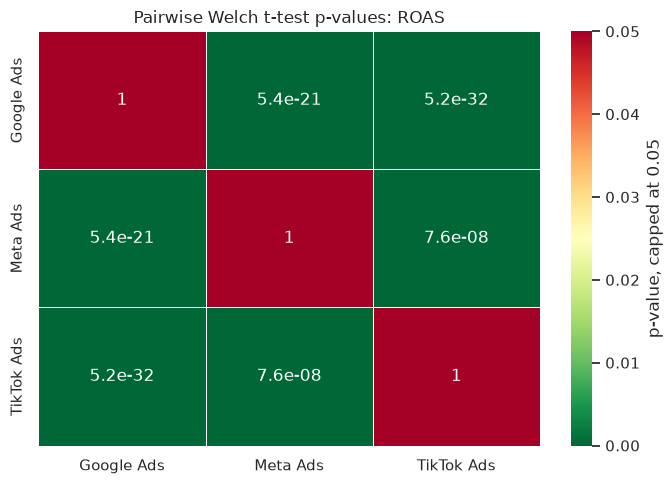

In [18]:
# P-value heatmap for the primary business metric, ROAS.
channels = sorted(df.channel.unique())
p_matrix = pd.DataFrame(1.0, index=channels, columns=channels)
for row in t_results.query("metric == 'roas'").itertuples():
    p_matrix.loc[row.group_a, row.group_b] = row.p_value
    p_matrix.loc[row.group_b, row.group_a] = row.p_value

plt.figure(figsize=(7, 5))
sns.heatmap(p_matrix, annot=True, fmt='.2g', cmap='RdYlGn_r', vmin=0, vmax=0.05,
            linewidths=0.5, cbar_kws={'label': 'p-value, capped at 0.05'})
plt.title('Pairwise Welch t-test p-values: ROAS')
plt.tight_layout()
plt.savefig(OUT / 'roas_pvalue_heatmap.png', dpi=160, bbox_inches='tight')
plt.show()

## 3. Binary outcome comparison with Fisher's exact test

For each channel pair, conversions and non-conversions are constructed from total clicks. This tests whether the click-level conversion odds differ. Because the counts are aggregated across campaign-day rows, the test can be extremely sensitive; practical differences in conversion rate are reported alongside the p-value.

In [ ]:
fisher_rows = []
for group_a, group_b in combinations(channels, 2):
    a = summary.loc[group_a]
    b = summary.loc[group_b]
    a_conv, a_non = int(a.conversions), int(a.clicks - a.conversions)
    b_conv, b_non = int(b.conversions), int(b.clicks - b.conversions)
    # Put group B first so the odds ratio is interpreted as B relative to A.
    odds_ratio, p_value = fisher_exact([[b_conv, b_non], [a_conv, a_non]], alternative='two-sided')
    fisher_rows.append({'group_a': group_a, 'group_b': group_b, 'clicks_a': int(a.clicks),
                       'clicks_b': int(b.clicks), 'conversions_a': a_conv, 'conversions_b': b_conv,
                       'conversion_rate_a': a.conversions / a.clicks,
                       'conversion_rate_b': b.conversions / b.clicks,
                       'rate_difference_b_minus_a': b.conversions / b.clicks - a.conversions / a.clicks,
                       'odds_ratio_b_vs_a': odds_ratio, 'p_value': p_value,
                       'significant_raw': p_value < ALPHA})
fisher_results = pd.DataFrame(fisher_rows)
fisher_results.to_csv(OUT / 'fisher_exact_tests.csv', index=False)
display(fisher_results.round({'conversion_rate_a': 4, 'conversion_rate_b': 4, 'rate_difference_b_minus_a': 4, 'odds_ratio_b_vs_a': 4, 'p_value': 6}))

In [ ]:
conv = df.groupby('channel')[['conversions', 'clicks']].sum()
conv['non_conversions'] = conv.clicks - conv.conversions
conv['conv_rate'] = conv.conversions / conv.clicks

rows = []
for a, b in combinations(sorted(conv.index), 2):
    table = [[int(conv.loc[b, 'conversions']), int(conv.loc[b, 'non_conversions'])],
             [int(conv.loc[a, 'conversions']), int(conv.loc[a, 'non_conversions'])]]
    odds_ratio, p = fisher_exact(table, alternative='two-sided')
    rate_a, rate_b = conv.loc[a, 'conv_rate'], conv.loc[b, 'conv_rate']
    rows.append({'group_a': a, 'group_b': b, 'conversion_rate_a': rate_a,
                 'conversion_rate_b': rate_b,
                 'difference_percentage_points': 100 * (rate_b - rate_a),
                 'percent_difference': 100 * (rate_b - rate_a) / rate_a,
                 'odds_ratio_b_vs_a': odds_ratio, 'p_value': p,
                 'significant': p < ALPHA})
fisher_res = pd.DataFrame(rows)
display(fisher_res.round(6))

In [ ]:
rate_plot = conv['conv_rate'].sort_values() * 100
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(rate_plot.index, rate_plot.values)
ax.bar_label(bars, fmt='%.2f%%', padding=4)
ax.set_xlabel('Conversion rate')
ax.set_title('Aggregate conversion rate by channel')
fig.tight_layout()
fig.savefig(OUT / 'rate_comparison.png', dpi=140, bbox_inches='tight')
plt.show()

cvr_t_res = t_results.query("metric == 'conversion_rate'").copy()
cvr_t_res['t_test_significant'] = cvr_t_res.p_value < ALPHA
comparison = fisher_res.merge(cvr_t_res[['group_a', 'group_b', 'p_value', 't_test_significant']],
                             on=['group_a', 'group_b'], suffixes=('_fisher', '_t_test'))
comparison['tests_agree'] = comparison.significant == comparison.t_test_significant
display(comparison[['group_a', 'group_b', 'p_value_fisher', 'p_value_t_test',
                    'significant', 't_test_significant', 'tests_agree']].round(6))

### Answers

1. **Significant differences:** Fisher's exact test finds significant differences for Google–Meta, Google–TikTok, and Meta–TikTok.
2. **Practical importance:** The differences are small: aggregate conversion rates are approximately 4.46% for Google, 4.59% for Meta, and 4.71% for TikTok. The largest gap is about 0.25 percentage points.
3. **Fisher versus t-test:** They do not agree. Fisher uses millions of clicks and detects these small gaps; the t-test uses hundreds of campaign-day observations and is not significant. They also make different independence assumptions and measure different quantities.

## 4. Multiple-comparison correction

Both Bonferroni and Benjamini–Hochberg (BH) adjustments are applied within each test family: each continuous metric's pairwise t-tests and the Fisher tests. Bonferroni controls family-wise error more conservatively; BH controls the expected false discovery rate.

In [ ]:
def add_corrections(results):
    results = results.copy()
    p = results.p_value.to_numpy()
    results['p_bonferroni'] = np.minimum(p * len(p), 1.0)
    results['p_bh'] = false_discovery_control(p, method='bh')
    results['significant_bonferroni'] = results.p_bonferroni < ALPHA
    results['significant_bh'] = results.p_bh < ALPHA
    return results

corrected_t = pd.concat([add_corrections(group) for _, group in t_results.groupby('metric', sort=False)], ignore_index=True)
corrected_fisher = add_corrections(fisher_results)
corrected_t.to_csv(OUT / 'pairwise_t_tests_corrected.csv', index=False)
corrected_fisher.to_csv(OUT / 'fisher_exact_tests_corrected.csv', index=False)

correction_summary = []
for name, result in [('CPA t-tests', corrected_t.query("metric == 'cpa'")),
                     ('ROAS t-tests', corrected_t.query("metric == 'roas'")),
                     ('Conversion-rate t-tests', corrected_t.query("metric == 'conversion_rate'")),
                     ('Fisher exact tests', corrected_fisher)]:
    correction_summary.append({'test_family': name, 'comparisons': len(result),
                              'raw_significant': int(result.significant_raw.sum()),
                              'bonferroni_significant': int(result.significant_bonferroni.sum()),
                              'bh_significant': int(result.significant_bh.sum())})
display(pd.DataFrame(correction_summary))

## 5. Power analysis

The following calculation uses the noncentral t distribution for a two-sided independent-samples test with equal future group sizes. It estimates the observations per group needed for 80% power at alpha = 0.05 for small, medium, and large Cohen's *d*. It also calculates observed power for the current pairwise ROAS comparisons.

In [ ]:
def t_test_power(effect_size, n_a, n_b=None, alpha=ALPHA):
    n_b = n_a if n_b is None else n_b
    dfree = n_a + n_b - 2
    ncp = abs(effect_size) * np.sqrt(n_a * n_b / (n_a + n_b))
    critical = stats.t.ppf(1 - alpha / 2, dfree)
    upper_tail = stats.nct.sf(critical, dfree, ncp)
    lower_tail = stats.nct.cdf(-critical, dfree, ncp)
    # SciPy may return NaN for an underflowed tail; that tail is effectively zero here.
    upper_tail = 0.0 if not np.isfinite(upper_tail) else upper_tail
    lower_tail = 0.0 if not np.isfinite(lower_tail) else lower_tail
    return float(np.clip(upper_tail + lower_tail, 0.0, 1.0))

def required_n_per_group(effect_size, target_power=0.80, alpha=ALPHA, max_n=10000):
    for n in range(2, max_n + 1):
        if t_test_power(effect_size, n) >= target_power:
            return n
    return np.nan

power_plan = pd.DataFrame({'cohens_d': [0.2, 0.5, 0.8]})
power_plan['interpretation'] = ['small', 'medium', 'large']
power_plan['required_n_per_group_for_80pct_power'] = power_plan.cohens_d.map(required_n_per_group)
power_plan.to_csv(OUT / 'power_sample_size_plan.csv', index=False)
display(power_plan)

roas_results = corrected_t.query("metric == 'roas'").copy()
roas_results['observed_power'] = roas_results.apply(lambda r: t_test_power(r.cohens_d, int(r.n_a), int(r.n_b)), axis=1)
display(roas_results[['group_a', 'group_b', 'n_a', 'n_b', 'cohens_d', 'observed_power']].round(3))

min_n = int(df.channel.value_counts().min())
medium_n = int(power_plan.loc[power_plan.cohens_d == 0.5, 'required_n_per_group_for_80pct_power'].iloc[0])
display(Markdown(f'**Planning implication:** the smallest current channel has {min_n:,} campaign-day observations, compared with {medium_n} per group for 80% power to detect a medium effect. Small effects require substantially more observations, and this calculation does not correct for repeated measurements or channel confounding.'))

## 6. Executive memo and recommendation

In [ ]:
best_roas = summary.roas.idxmax()
best_cpa = summary.cpa.idxmin()
roas_all_bh = bool(roas_results.significant_bh.all())
conversion_t_tests = corrected_t.query("metric == 'conversion_rate'")
conversion_t_bh_count = int(conversion_t_tests.significant_bh.sum())

# This is a cautious three-platform test allocation, not a claim that spend scales linearly.
allocation = pd.DataFrame({'channel': ['TikTok Ads', 'Meta Ads', 'Google Ads', 'Validation reserve'],
                          'share': [0.45, 0.30, 0.15, 0.10]})
allocation['monthly_amount'] = allocation.share * 500_000
allocation.to_csv(OUT / 'illustrative_500k_allocation.csv', index=False)
display(allocation.style.format({'share': '{:.0%}', 'monthly_amount': '${:,.0f}'}))

memo = f'''# Executive memo: provisional channel budget recommendation

## Finding

Across {len(df):,} campaign-day observations, {best_roas} had the highest aggregate ROAS ({summary.loc[best_roas, 'roas']:.2f}x) and {best_cpa} had the lowest aggregate CPA (${summary.loc[best_cpa, 'cpa']:.2f}). Pairwise ROAS Welch tests remained significant after both Bonferroni and Benjamini–Hochberg correction: {roas_all_bh}. The ROAS effects range from medium to large, so the differences are practically meaningful in this dataset.

Aggregate conversion rates were close ({summary.loc['Google Ads', 'conversion_rate']:.2%} Google, {summary.loc['Meta Ads', 'conversion_rate']:.2%} Meta, and {summary.loc['TikTok Ads', 'conversion_rate']:.2%} TikTok). The pooled-click Fisher tests are statistically significant, while the row-level conversion-rate t-tests have {conversion_t_bh_count} BH-significant pair(s). This contrast suggests that statistical significance is being driven partly by very large click counts; conversion-rate differences should not be treated as large commercial effects without a controlled experiment.

## Provisional $500,000 plan

The supplied data has three platforms rather than seven channels, so the following is an illustrative starting point only:

- TikTok Ads: 45% ($225,000)
- Meta Ads: 30% ($150,000)
- Google Ads: 15% ($75,000)
- Validation reserve: 10% ($50,000)

The reserve should fund randomized holdouts, creative tests, and measurement. Before reallocating the full budget, obtain comparable data for the four missing channels and validate whether the observed ROAS ranking persists after controlling for campaign type, industry, country, seasonality, and spend level.

## Caveats and next steps

These are observational campaign-day comparisons, not causal estimates. Rows may share campaigns, audiences, or dates, and aggregate Fisher tests treat clicks as independent. ROAS and CPA can also be skewed by attribution and outliers. Use the current results to prioritize tests, not to promise incremental returns. The power analysis indicates adequate row counts for medium effects, but small effects need larger or better-designed experiments.'''
display(Markdown(memo))
(OUT / 'executive_memo.md').write_text(memo, encoding='utf-8')
print(f'Wrote analysis artifacts to {OUT.resolve()}')